# 02. Основні A/B-тести

Крок 6 плану. Правила зафіксовано в `docs/experiment_design.md`:

- H1: Mens vs контроль, H2: Womens vs контроль, H3: Mens vs Womens. Двосторонні тести, α = 0,05.
- **Primary-метрика одна: `conversion`.** Secondary: `visit`, `spend` на клієнта, `spend` серед покупців.
- Поправка Holm (Bonferroni для порівняння) окремо в кожній метриці.
- Рішення: приріст конверсії значущий після Holm і додатний **та** додатковий `spend` на отримувача більший за вартість листа `c`.

Усі різниці рахуються як «перша група мінус друга». Функції в `src/ab_stats.py`, тести в `tests/test_ab_stats.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from statsmodels.stats.power import TTestIndPower

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import ab_stats as ab
from load_data import URI

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

engine = create_engine(URI.replace("postgresql://", "postgresql+psycopg2://", 1))
df = pd.read_sql("""
    SELECT c.*, a.segment, o.visit, o.conversion, o.spend
    FROM customers c
    JOIN assignments a USING (customer_id)
    JOIN outcomes   o USING (customer_id)
    ORDER BY c.customer_id
""", engine)
df[["history", "spend"]] = df[["history", "spend"]].astype(float)

CONTROL, MENS, WOMENS = "No E-Mail", "Mens E-Mail", "Womens E-Mail"
PAIRS = [("H1", MENS, CONTROL), ("H2", WOMENS, CONTROL), ("H3", MENS, WOMENS)]
groups = {name: part for name, part in df.groupby("segment")}
print({k: len(v) for k, v in groups.items()})

{'Mens E-Mail': 21307, 'No E-Mail': 21306, 'Womens E-Mail': 21387}


## 1. Conversion (primary) і visit: z-тест для двох пропорцій

In [2]:
def row(metric, role, h, a, b, test, r=None, **extra):
    base = {"metric": metric, "role": role, "hypothesis": h, "group": a, "baseline": b, "test": test}
    if r is not None:
        base.update(value_group=r.estimate1, value_baseline=r.estimate2, diff=r.diff,
                    ci_low=r.ci_low, ci_high=r.ci_high, relative_lift=r.relative_lift,
                    statistic=r.statistic, p_raw=r.p_value)
    base.update(extra)
    return base


rows = []
for metric, role in [("conversion", "primary"), ("visit", "secondary")]:
    for h, a, b in PAIRS:
        x, y = groups[a][metric], groups[b][metric]
        r = ab.two_proportion_test(int(x.sum()), len(x), int(y.sum()), len(y))
        rows.append(row(metric, role, h, a, b, "two-proportion z", r))

## 2. Spend на клієнта (з нулями): Welch, bootstrap, Mann-Whitney

Welch порівнює середні, bootstrap дає ДІ без припущення про нормальність, Mann-Whitney перевіряє зсув розподілу за рангами (це не тест середніх).

In [3]:
for h, a, b in PAIRS:
    x, y = groups[a]["spend"], groups[b]["spend"]
    r = ab.welch_test(x, y)
    _, boot_low, boot_high = ab.bootstrap_mean_diff_ci(x, y, n_boot=10_000, seed=42)
    rows.append(row("spend_per_customer", "secondary", h, a, b, "Welch t", r,
                    boot_ci_low=boot_low, boot_ci_high=boot_high, p_mannwhitney=ab.mann_whitney_p(x, y)))

## 3. Spend серед покупців

Лише bootstrap ДІ, без p-value: покупців мало, а сама вибірка покупців залежить від листа, тому це порівняння не є причинним ефектом листа.

In [4]:
for h, a, b in PAIRS:
    x = groups[a].loc[groups[a].conversion == 1, "spend"]
    y = groups[b].loc[groups[b].conversion == 1, "spend"]
    diff, low, high = ab.bootstrap_mean_diff_ci(x, y, n_boot=10_000, seed=42)
    rows.append(row("spend_per_buyer", "secondary", h, a, b, "bootstrap CI only",
                    value_group=x.mean(), value_baseline=y.mean(), diff=diff, relative_lift=diff / y.mean(),
                    boot_ci_low=low, boot_ci_high=high, n_group=len(x), n_baseline=len(y)))

## 4. Множинні порівняння: Holm і Bonferroni (сім'я з трьох тестів на метрику)

In [5]:
res = pd.DataFrame(rows)
res["n_group"] = res["n_group"].fillna(res["group"].map(df.segment.value_counts())).astype(int)
res["n_baseline"] = res["n_baseline"].fillna(res["baseline"].map(df.segment.value_counts())).astype(int)

for metric, part in res[res.p_raw.notna()].groupby("metric"):
    res.loc[part.index, "p_holm"] = ab.holm(part.p_raw)
    res.loc[part.index, "p_bonferroni"] = ab.bonferroni(part.p_raw)
mw = res.p_mannwhitney.notna()
res.loc[mw, "p_mannwhitney_holm"] = ab.holm(res.loc[mw, "p_mannwhitney"])
res["significant_holm"] = np.where(res.p_holm.notna(), res.p_holm < 0.05, None)

# cross-check with SQL (results/08_group_comparison_cte.csv)
sql = pd.read_csv(ROOT / "results" / "08_group_comparison_cte.csv").set_index("hypothesis")
for metric, col, scale in [("conversion", "conv_diff_pp", 100), ("visit", "visit_diff_pp", 100),
                           ("spend_per_customer", "avg_spend_diff", 1)]:
    py = res[res.metric == metric].set_index("hypothesis")["diff"] * scale
    assert np.allclose(py, sql.loc[py.index, col], atol=0.006), metric
print("Python differences match SQL")

res[["metric", "hypothesis", "diff", "ci_low", "ci_high", "relative_lift", "p_raw", "p_holm", "p_bonferroni"]]

Python differences match SQL


,metric,hypothesis,diff,ci_low,ci_high,relative_lift,p_raw,p_holm,p_bonferroni
0,conversion,H1,0.006805,0.005000,0.008610,1.188422,1.523224e-13,4.569671e-13,4.569671e-13
1,conversion,H2,0.003111,0.001499,0.004723,0.543313,1.571051e-04,3.142103e-04,4.713154e-04
2,conversion,H3,0.003694,0.001744,0.005644,0.418003,2.051538e-04,3.142103e-04,6.154613e-04
3,visit,H1,0.076590,0.069954,0.083226,0.721405,5.685165e-112,1.705550e-111,1.705550e-111
4,visit,H2,0.045233,0.038894,0.051572,0.426055,3.182403e-44,6.364806e-44,9.547209e-44
5,visit,H3,0.031356,0.024285,0.038428,0.207109,3.802165e-18,3.802165e-18,1.140650e-17
6,spend_per_customer,H1,0.769827,0.485140,1.054515,1.179289,1.163815e-07,3.491445e-07,3.491445e-07
7,spend_per_customer,H2,0.424412,0.168957,0.679868,0.650152,1.129397e-03,2.258794e-03,3.388191e-03
8,spend_per_customer,H3,0.345415,0.032561,0.658268,0.320660,3.046865e-02,3.046865e-02,9.140595e-02
9,spend_per_buyer,H1,-0.475776,NaN,NaN,-0.004173,NaN,NaN,NaN


In [6]:
for _, r in res[res.metric.isin(["conversion", "visit"])].iterrows():
    print(f"{r.metric:<11}{r.hypothesis}  {r.value_group:.3%} vs {r.value_baseline:.3%}  "
          f"diff {100 * r['diff']:+.3f} pp  CI [{100 * r.ci_low:+.3f}; {100 * r.ci_high:+.3f}]  "
          f"lift {r.relative_lift:+.1%}  p {r.p_raw:.2e}  Holm {r.p_holm:.2e}  Bonf {r.p_bonferroni:.2e}")
print()
for _, r in res[res.metric == "spend_per_customer"].iterrows():
    print(f"spend       {r.hypothesis}  {r.value_group:.4f} vs {r.value_baseline:.4f}  diff {r['diff']:+.4f}  "
          f"Welch CI [{r.ci_low:+.4f}; {r.ci_high:+.4f}]  boot CI [{r.boot_ci_low:+.4f}; {r.boot_ci_high:+.4f}]  "
          f"p {r.p_raw:.2e}  Holm {r.p_holm:.2e}  MW {r.p_mannwhitney:.2e}  MW-Holm {r.p_mannwhitney_holm:.2e}")
print()
for _, r in res[res.metric == "spend_per_buyer"].iterrows():
    print(f"per buyer   {r.hypothesis}  {r.value_group:.2f} (n={r.n_group}) vs {r.value_baseline:.2f} (n={r.n_baseline})  "
          f"diff {r['diff']:+.2f}  boot CI [{r.boot_ci_low:+.2f}; {r.boot_ci_high:+.2f}]")

conversion H1  1.253% vs 0.573%  diff +0.681 pp  CI [+0.500; +0.861]  lift +118.8%  p 1.52e-13  Holm 4.57e-13  Bonf 4.57e-13
conversion H2  0.884% vs 0.573%  diff +0.311 pp  CI [+0.150; +0.472]  lift +54.3%  p 1.57e-04  Holm 3.14e-04  Bonf 4.71e-04
conversion H3  1.253% vs 0.884%  diff +0.369 pp  CI [+0.174; +0.564]  lift +41.8%  p 2.05e-04  Holm 3.14e-04  Bonf 6.15e-04
visit      H1  18.276% vs 10.617%  diff +7.659 pp  CI [+6.995; +8.323]  lift +72.1%  p 5.69e-112  Holm 1.71e-111  Bonf 1.71e-111
visit      H2  15.140% vs 10.617%  diff +4.523 pp  CI [+3.889; +5.157]  lift +42.6%  p 3.18e-44  Holm 6.36e-44  Bonf 9.55e-44
visit      H3  18.276% vs 15.140%  diff +3.136 pp  CI [+2.429; +3.843]  lift +20.7%  p 3.80e-18  Holm 3.80e-18  Bonf 1.14e-17

spend       H1  1.4226 vs 0.6528  diff +0.7698  Welch CI [+0.4851; +1.0545]  boot CI [+0.4882; +1.0582]  p 1.16e-07  Holm 3.49e-07  MW 1.58e-13  MW-Holm 4.75e-13
spend       H2  1.0772 vs 0.6528  diff +0.4244  Welch CI [+0.1690; +0.6799]  boot C

## 5. Power: чи вистачало даних

Потужність 80 %. Базова конверсія та n беруться з контрольної групи. Порівнюємо з таблицею в `experiment_design.md`.

In [7]:
ctrl = groups[CONTROL]
n, p0 = len(ctrl), ctrl.conversion.mean()
p_w, v0 = groups[WOMENS].conversion.mean(), ctrl.visit.mean()
for label, alpha in [("alpha = 0.05", 0.05), ("alpha = 0.05/3", 0.05 / 3)]:
    mde = ab.mde_two_proportions(n, p0, alpha)
    print(f"{label:<16} conversion vs control: MDE {100 * mde:.3f} pp ({mde / p0:.0%} relative)")
mde_h3 = ab.mde_two_proportions(n, p_w, 0.05 / 3)
print(f"alpha = 0.05/3   Mens vs Womens (base {p_w:.3%}): MDE {100 * mde_h3:.3f} pp")
print(f"alpha = 0.05/3   visit vs control: MDE {100 * ab.mde_two_proportions(n, v0, 0.05 / 3):.3f} pp")
d = TTestIndPower().solve_power(effect_size=None, nobs1=n, alpha=0.05 / 3, power=0.8)
for label, sd in [("control sd (as in design)", ctrl.spend.std()), ("sd of all customers", df.spend.std())]:
    print(f"alpha = 0.05/3   spend per customer: d = {d:.4f}, MDE = {d * sd:.3f} using {label} = {sd:.2f}")

sizes = pd.DataFrame(
    [{"uplift_pp": u, "n_alpha_0.05": ab.sample_size_two_proportions(p0, u / 100, 0.05),
      "n_alpha_0.0167": ab.sample_size_two_proportions(p0, u / 100, 0.05 / 3)} for u in (0.2, 0.3, 0.5)])
sizes

alpha = 0.05     conversion vs control: MDE 0.223 pp (39% relative)
alpha = 0.05/3   conversion vs control: MDE 0.261 pp (46% relative)
alpha = 0.05/3   Mens vs Womens (base 0.884%): MDE 0.317 pp
alpha = 0.05/3   visit vs control: MDE 0.985 pp
alpha = 0.05/3   spend per customer: d = 0.0313, MDE = 0.363 using control sd (as in design) = 11.59
alpha = 0.05/3   spend per customer: d = 0.0313, MDE = 0.471 using sd of all customers = 15.04


,uplift_pp,n_alpha_0.05,n_alpha_0.0167
0,0.2,26074,34778
1,0.3,12377,16509
2,0.5,5003,6673


## 6. Бізнес-розрахунок і критерій рішення

Вартість листа `c` у даних **відсутня**, це припущення. Тому показуємо чутливість: безубиткове `c` дорівнює оціненому додатковому доходу на отримувача. Рахуємо лише виручку, без маржі.

In [8]:
spend = res[res.metric == "spend_per_customer"].set_index("hypothesis")
costs = [0.05, 0.10, 0.25, 0.50, 1.00]  # assumed cost of one e-mail
biz = []
for h, name in [("H1", MENS), ("H2", WOMENS)]:
    r = spend.loc[h]
    for c in costs:
        biz.append({"email": name, "assumed_cost": c, "break_even_cost": r["diff"],
                    "net_per_1000": ab.net_revenue_per_1000(r["diff"], c),
                    "net_per_1000_ci_low": ab.net_revenue_per_1000(r.boot_ci_low, c),
                    "net_per_1000_ci_high": ab.net_revenue_per_1000(r.boot_ci_high, c)})
biz = pd.DataFrame(biz)
biz.round(3)

,email,assumed_cost,break_even_cost,net_per_1000,net_per_1000_ci_low,net_per_1000_ci_high
0,Mens E-Mail,0.05,0.770,719.827,438.210,1008.220
1,Mens E-Mail,0.10,0.770,669.827,388.210,958.220
2,Mens E-Mail,0.25,0.770,519.827,238.210,808.220
3,Mens E-Mail,0.50,0.770,269.827,-11.790,558.220
4,Mens E-Mail,1.00,0.770,-230.173,-511.790,58.220
5,Womens E-Mail,0.05,0.424,374.412,120.911,627.457
6,Womens E-Mail,0.10,0.424,324.412,70.911,577.457
7,Womens E-Mail,0.25,0.424,174.412,-79.089,427.457
8,Womens E-Mail,0.50,0.424,-75.588,-329.089,177.457
9,Womens E-Mail,1.00,0.424,-575.588,-829.089,-322.543


In [9]:
conv = res[res.metric == "conversion"].set_index("hypothesis")
for h, name in [("H1", MENS), ("H2", WOMENS)]:
    c1 = bool(conv.loc[h, "p_holm"] < 0.05 and conv.loc[h, "diff"] > 0)
    r = spend.loc[h]
    print(f"{name}: condition 1 (conversion up, Holm p = {conv.loc[h, 'p_holm']:.2e}) -> {c1}; "
          f"condition 2 holds while c < {r['diff']:.3f} (bootstrap 95% CI {r.boot_ci_low:.3f} .. {r.boot_ci_high:.3f})")
print(f"H3: Mens - Womens conversion Holm p = {conv.loc['H3', 'p_holm']:.4f}; "
      f"spend diff {spend.loc['H3', 'diff']:+.3f}, Welch Holm p = {spend.loc['H3', 'p_holm']:.4f}")

Mens E-Mail: condition 1 (conversion up, Holm p = 4.57e-13) -> True; condition 2 holds while c < 0.770 (bootstrap 95% CI 0.488 .. 1.058)
Womens E-Mail: condition 1 (conversion up, Holm p = 3.14e-04) -> True; condition 2 holds while c < 0.424 (bootstrap 95% CI 0.171 .. 0.677)
H3: Mens - Womens conversion Holm p = 0.0003; spend diff +0.345, Welch Holm p = 0.0305


## 7. Сегментний аналіз (дослідницький)

**Це гіпотези для наступного тесту, а не висновки.** Інтервали 95 % без поправки на множинні порівняння, p-value навмисно не показуємо, у критерій рішення ці результати не входять. `Surburban` лишено, як в оригіналі.

In [10]:
df["recency_band"] = pd.cut(df.recency, [0, 3, 6, 12], labels=["1-3", "4-6", "7-12"]).astype(str)
seg_rows = []
for dim in ["newbie", "channel", "zip_code", "history_segment", "recency_band"]:
    for level, part in df.groupby(dim):
        c = part[part.segment == CONTROL]
        for name in (MENS, WOMENS):
            t = part[part.segment == name]
            r = ab.two_proportion_test(int(t.conversion.sum()), len(t), int(c.conversion.sum()), len(c))
            s_diff, s_low, s_high = ab.bootstrap_mean_diff_ci(t.spend, c.spend, n_boot=5_000, seed=42)
            seg_rows.append({"dimension": dim, "level": str(level), "email": name,
                             "n_email": len(t), "n_control": len(c),
                             "buyers_email": int(t.conversion.sum()), "buyers_control": int(c.conversion.sum()),
                             "conv_uplift_pp": 100 * r.diff, "conv_ci_low_pp": 100 * r.ci_low,
                             "conv_ci_high_pp": 100 * r.ci_high,
                             "spend_uplift": s_diff, "spend_ci_low": s_low, "spend_ci_high": s_high})
seg = pd.DataFrame(seg_rows)
print("segments:", len(seg), " CI above zero (conversion):", int((seg.conv_ci_low_pp > 0).sum()),
      " negative point estimates:", int((seg.conv_uplift_pp < 0).sum()))
seg[["dimension", "level", "email", "buyers_email", "buyers_control", "conv_uplift_pp", "conv_ci_low_pp", "conv_ci_high_pp"]].round(3)

segments: 36  CI above zero (conversion): 26  negative point estimates: 2


,dimension,level,email,buyers_email,buyers_control,conv_uplift_pp,conv_ci_low_pp,conv_ci_high_pp
0,newbie,0,Mens E-Mail,148,82,0.621,0.342,0.899
1,newbie,0,Womens E-Mail,92,82,0.093,-0.149,0.336
2,newbie,1,Mens E-Mail,119,40,0.740,0.509,0.970
3,newbie,1,Womens E-Mail,97,40,0.527,0.314,0.740
4,channel,Multichannel,Mens E-Mail,44,18,1.017,0.424,1.609
5,channel,Multichannel,Womens E-Mail,36,18,0.705,0.152,1.258
6,channel,Phone,Mens E-Mail,100,50,0.546,0.288,0.804
7,channel,Phone,Womens E-Mail,67,50,0.173,-0.052,0.397
8,channel,Web,Mens E-Mail,123,54,0.720,0.446,0.994
9,channel,Web,Womens E-Mail,86,54,0.343,0.097,0.590


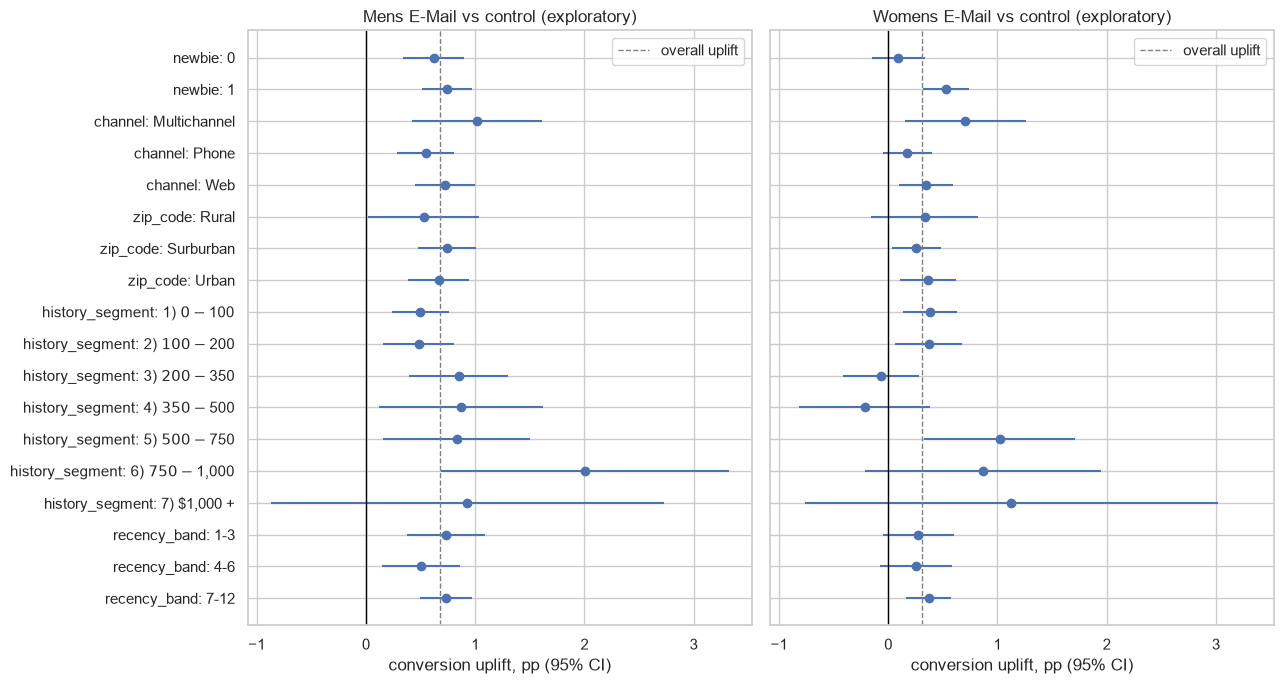

In [11]:
labels = (seg.dimension + ": " + seg.level).drop_duplicates().tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True, sharex=True)
for ax, name, h in zip(axes, (MENS, WOMENS), ("H1", "H2")):
    p = seg[seg.email == name]
    y = np.arange(len(p))
    ax.errorbar(p.conv_uplift_pp, y, fmt="o",
                xerr=[p.conv_uplift_pp - p.conv_ci_low_pp, p.conv_ci_high_pp - p.conv_uplift_pp])
    ax.axvline(0, color="black", lw=1)
    ax.axvline(100 * conv.loc[h, "diff"], color="grey", ls="--", lw=1, label="overall uplift")
    ax.set_title(f"{name} vs control (exploratory)")
    ax.set_xlabel("conversion uplift, pp (95% CI)")
    ax.legend()
axes[0].set_yticks(np.arange(len(labels)), labels)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

## 8. Збереження результатів (для Power BI і README)

In [12]:
out = ROOT / "data" / "processed"
cols = ["metric", "role", "hypothesis", "group", "baseline", "test", "n_group", "n_baseline",
        "value_group", "value_baseline", "diff", "ci_low", "ci_high", "boot_ci_low", "boot_ci_high",
        "relative_lift", "statistic", "p_raw", "p_holm", "p_bonferroni", "p_mannwhitney",
        "p_mannwhitney_holm", "significant_holm"]
res[cols].to_csv(out / "test_results.csv", index=False)
seg.to_csv(out / "segment_uplift.csv", index=False)
biz.to_csv(out / "business_sensitivity.csv", index=False)
print("saved test_results.csv, segment_uplift.csv, business_sensitivity.csv to data/processed/")

saved test_results.csv, segment_uplift.csv, business_sensitivity.csv to data/processed/


## Підсумок

| Гіпотеза | Конверсія: різниця, п.п. [95 % ДІ] | p сирий → Holm | Висновок |
|---|---|---|---|
| H1 Mens vs контроль | +0,681 [+0,500; +0,861] | 1,5·10⁻¹³ → 4,6·10⁻¹³ | Чоловічий лист підвищує конверсію (+118,8 % відносно контролю). |
| H2 Womens vs контроль | +0,311 [+0,150; +0,472] | 1,6·10⁻⁴ → 3,1·10⁻⁴ | Жіночий лист підвищує конверсію (+54,3 %). |
| H3 Mens vs Womens | +0,369 [+0,174; +0,564] | 2,1·10⁻⁴ → 3,1·10⁻⁴ | Чоловічий лист дає вищу конверсію, ніж жіночий (+41,8 %). |

**Secondary.**
- `visit`: усі три різниці значущі (+7,66 / +4,52 / +3,14 п.п.).
- `spend` на клієнта: H1 +0,770 [0,485; 1,055], H2 +0,424 [0,169; 0,680], H3 +0,345 [0,033; 0,658]; bootstrap ДІ майже збігаються з Welch. H3 значуща за Holm (p = 0,030), але не за Bonferroni (p = 0,091), тож це найслабший результат.
- `spend` серед покупців: усі bootstrap ДІ містять нуль. Різниці в чеку не виявлено (це не доводить, що її немає).

**Power.** Для приросту 0,3 п.п. потрібно 12 377 клієнтів на групу (α = 0,05) або 16 509 (α = 0,05/3), маємо ≈ 21 300. MDE для конверсії проти контролю 0,22 / 0,26 п.п. Даних вистачало для ефектів такого масштабу, але не для приростів 0,1–0,2 п.п.

**Рішення.** Обидва листи виконують умову 1. Умова 2 виконується, поки вартість листа `c` менша за 0,770 (Mens) і 0,424 (Womens) виручки на отримувача (95 % ДІ: 0,49–1,06 і 0,17–0,68). За критерієм дизайну **запускати чоловічий лист**, якщо `c` < 0,770: у нього вищий додатковий дохід і значуще вища конверсія, ніж у жіночого. Це виручка без маржі, а `c` є припущенням.

**Сегменти (дослідницьке).** 26 з 36 інтервалів конверсії вищі за нуль, 2 точкові оцінки від'ємні (Womens у `history_segment` 200–500). Гіпотеза для наступного тесту: жіночий лист майже не діє на наявних клієнтів (+0,09 п.п.), але діє на нових (+0,53 п.п.). Взаємодію формально не тестували.